<a href="https://colab.research.google.com/github/risinukaviranga/ci-cd-build-failure-prediction/blob/main/Data_understanding.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


01. Project Introduction
02. Import Libraries
03. Connect Google Drive
04. Configure DuckDB
05. Load Dataset Information
06. Dataset Structure
07. Column Names and Data Types
08. Dataset Sample Records
09. Target Variable Investigation
10. Missing Value Analysis
11. Duplicate Analysis
12. Initial Statistical Summary
13. Export Dataset Reports
14. Findings and Conclusion

In [1]:

# PipelineX – CI/CD Build Failure Prediction

## Milestone 01: Dataset Understanding

### Project Objective
The objective of this project is to develop a
Machine Learning model that predicts whether a
CI/CD pipeline build will pass or fail.

### Dataset
TravisTorrent Dataset

### Dataset Source
https://figshare.com/articles/dataset/TravisTorrent/19314170

### Main Tasks
1. Understand dataset structure.
2. Identify feature columns and data types.
3. Investigate the target variable.
4. Analyze missing values.
5. Identify duplicate records.
6. Generate initial dataset reports.

### Technologies
- Python
- Pandas
- NumPy
- DuckDB
- Google Colab


SyntaxError: invalid syntax (2119869862.py, line 6)

Importing necessary libraries

In [2]:
# Install required libraries
%pip install -q duckdb pandas numpy pyarrow matplotlib seaborn

In [3]:
# Import libraries

import os
import duckdb
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

print("All libraries imported successfully!")
print("DuckDB version:", duckdb.__version__)
print("Pandas version:", pd.__version__)

All libraries imported successfully!
DuckDB version: 1.3.2
Pandas version: 2.2.3


Connect with the dataset that uploaded to google drive

In [4]:
# Connect Google Drive

from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
# Dataset path
#check connection of the dataset

DATASET_PATH = (
    "/content/drive/MyDrive/PipelineX/travistorrent.csv"
)

# Check whether the dataset exists

if os.path.exists(DATASET_PATH):

    print("Dataset found successfully!")

    file_size = os.path.getsize(DATASET_PATH)

    print(f"Dataset size: {file_size / (1024**3):.2f} GB")

else:

    print("Dataset not found. Check your file path.")

Dataset found successfully!
Dataset size: 3.31 GB


Configuration of DuckDB

In [6]:
# Configure DuckDB

DB_PATH = "/content/pipelinex.duckdb"

TEMP_PATH = "/content/duckdb_temp"

os.makedirs(TEMP_PATH, exist_ok=True)

con = duckdb.connect(DB_PATH)

# Memory configuration
con.execute("SET memory_limit = '4GB'")

# CPU configuration
con.execute("SET threads = 2")

# Temporary storage
con.execute(f"SET temp_directory = '{TEMP_PATH}'")

print("DuckDB configured successfully!")

print(
    con.execute("SELECT version()").fetchone()
)

DuckDB configured successfully!
('v1.3.2',)


Load dataset information

In [7]:
# Prepare dataset path for DuckDB

csv_path = DATASET_PATH.replace("'", "''")

print("Dataset path configured.")

Dataset path configured.


In [8]:
# Read dataset schema

schema_query = f"""
DESCRIBE
SELECT *
FROM read_csv_auto(
    '{csv_path}',
    sample_size = 100000
)
"""

schema = con.execute(schema_query).df()

print("Dataset schema retrieved successfully!")

display(schema)

Dataset schema retrieved successfully!


,column_name,column_type,null,key,default,extra
0,tr_build_id,BIGINT,YES,None,None,None
1,gh_project_name,VARCHAR,YES,None,None,None
2,gh_is_pr,BOOLEAN,YES,None,None,None
3,gh_pr_created_at,VARCHAR,YES,None,None,None
4,gh_pull_req_num,VARCHAR,YES,None,None,None
...,...,...,...,...,...,...
61,tr_log_buildduration,VARCHAR,YES,None,None,None
62,tr_original_commit,VARCHAR,YES,None,None,None
63,tr_duration,VARCHAR,YES,None,None,None
64,tr_status,VARCHAR,YES,None,None,None


In [9]:
# Create reports directory

REPORT_DIR = "/content/drive/MyDrive/PipelineX/reports"

os.makedirs(REPORT_DIR, exist_ok=True)

# Save schema

schema.to_csv(
    f"{REPORT_DIR}/dataset_schema.csv",
    index=False
)

print("Schema saved successfully!")

Schema saved successfully!


Dataset dimensions investigation

In [10]:
# Get dataset dimensions

count_query = f"""
SELECT COUNT(*)
FROM read_csv_auto('{csv_path}')
"""

total_rows = con.execute(count_query).fetchone()[0]

total_columns = len(schema)

print("DATASET DIMENSIONS")
print("------------------")

print(f"Total rows: {total_rows:,}")
print(f"Total columns: {total_columns}")

print(
    f"Total records: {total_rows:,}"
)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

DATASET DIMENSIONS
------------------
Total rows: 3,881,992
Total columns: 66
Total records: 3,881,992


Investigate column names and data types

In [11]:
# Display all column names

print("TOTAL FEATURES:", len(schema))

for index, row in schema.iterrows():

    print(
        f"{index + 1:02d}. "
        f"{row['column_name']} "
        f"({row['column_type']})"
    )

TOTAL FEATURES: 66
01. tr_build_id (BIGINT)
02. gh_project_name (VARCHAR)
03. gh_is_pr (BOOLEAN)
04. gh_pr_created_at (VARCHAR)
05. gh_pull_req_num (VARCHAR)
06. gh_lang (VARCHAR)
07. git_merged_with (VARCHAR)
08. git_branch (VARCHAR)
09. gh_num_commits_in_push (VARCHAR)
10. gh_commits_in_push (VARCHAR)
11. git_prev_commit_resolution_status (VARCHAR)
12. git_prev_built_commit (VARCHAR)
13. tr_prev_build (VARCHAR)
14. gh_first_commit_created_at (VARCHAR)
15. gh_team_size (BIGINT)
16. git_all_built_commits (VARCHAR)
17. git_num_all_built_commits (BIGINT)
18. git_trigger_commit (VARCHAR)
19. tr_virtual_merged_into (VARCHAR)
20. gh_num_issue_comments (VARCHAR)
21. gh_num_commit_comments (BIGINT)
22. gh_num_pr_comments (VARCHAR)
23. git_diff_src_churn (BIGINT)
24. git_diff_test_churn (BIGINT)
25. gh_diff_files_added (BIGINT)
26. gh_diff_files_deleted (BIGINT)
27. gh_diff_files_modified (BIGINT)
28. gh_diff_tests_added (BIGINT)
29. gh_diff_tests_deleted (BIGINT)
30. gh_diff_src_files (BIGINT

In [12]:
# Identify numerical columns

numerical_columns = schema[
    schema["column_type"].str.contains(
        "INT|FLOAT|DOUBLE|DECIMAL",
        case=False,
        regex=True
    )
]

# Identify categorical/text columns

categorical_columns = schema[
    schema["column_type"].str.contains(
        "VARCHAR|TEXT",
        case=False,
        regex=True
    )
]

# Identify boolean columns

boolean_columns = schema[
    schema["column_type"].str.contains(
        "BOOLEAN",
        case=False,
        regex=True
    )
]

# Identify date/time columns

datetime_columns = schema[
    schema["column_type"].str.contains(
        "DATE|TIME",
        case=False,
        regex=True
    )
]

print("NUMERICAL COLUMNS:", len(numerical_columns))
print("CATEGORICAL COLUMNS:", len(categorical_columns))
print("BOOLEAN COLUMNS:", len(boolean_columns))
print("DATETIME COLUMNS:", len(datetime_columns))

NUMERICAL COLUMNS: 23
CATEGORICAL COLUMNS: 38
BOOLEAN COLUMNS: 4
DATETIME COLUMNS: 1


Display sample records

In [14]:
# Extract 1000 sample records

sample_query = f"""
SELECT *
FROM read_csv_auto('{csv_path}')
LIMIT 1000
"""

sample_df = con.execute(sample_query).df()

print("Sample records retrieved!")

display(sample_df.head(10))

Sample records retrieved!


,tr_build_id,gh_project_name,gh_is_pr,gh_pr_created_at,gh_pull_req_num,gh_lang,git_merged_with,git_branch,gh_num_commits_in_push,gh_commits_in_push,...,tr_log_num_test_suites_run,tr_log_num_test_suites_ok,tr_log_num_test_suites_failed,tr_log_tests_failed,tr_log_testduration,tr_log_buildduration,tr_original_commit,tr_duration,tr_status,tr_jobs
0,3154,rspec/rspec-core,False,NA,NA,ruby,None,master,NA,NA,...,NA,NA,NA,None,114.83,NA,029e6972fcf719542deff1b2619d2945146e84da,956,passed,"[3161, 3163, 3160, 3162, 3164]"
1,3154,rspec/rspec-core,False,NA,NA,ruby,None,master,NA,NA,...,NA,NA,NA,None,171.37,NA,029e6972fcf719542deff1b2619d2945146e84da,956,passed,"[3161, 3163, 3160, 3162, 3164]"
2,3154,rspec/rspec-core,False,NA,NA,ruby,None,master,NA,NA,...,NA,NA,NA,None,177.02,NA,029e6972fcf719542deff1b2619d2945146e84da,956,passed,"[3161, 3163, 3160, 3162, 3164]"
3,3154,rspec/rspec-core,False,NA,NA,ruby,None,master,NA,NA,...,NA,NA,NA,None,182.05,NA,029e6972fcf719542deff1b2619d2945146e84da,956,passed,"[3161, 3163, 3160, 3162, 3164]"
4,3154,rspec/rspec-core,False,NA,NA,ruby,None,master,NA,NA,...,NA,NA,NA,None,113.26,NA,029e6972fcf719542deff1b2619d2945146e84da,956,passed,"[3161, 3163, 3160, 3162, 3164]"
5,3211,ruby-amqp/amqp,False,NA,NA,ruby,None,master,NA,NA,...,NA,NA,NA,None,31.61,NA,7fc267b949209b189fa76f232f7e88a9b938b363,391,passed,"[3214, 3215, 3212, 3216, 3213]"
6,3211,ruby-amqp/amqp,False,NA,NA,ruby,None,master,NA,NA,...,NA,NA,NA,None,31.04,NA,7fc267b949209b189fa76f232f7e88a9b938b363,391,passed,"[3214, 3215, 3212, 3216, 3213]"
7,3211,ruby-amqp/amqp,False,NA,NA,ruby,None,master,NA,NA,...,NA,NA,NA,None,31.15,NA,7fc267b949209b189fa76f232f7e88a9b938b363,391,passed,"[3214, 3215, 3212, 3216, 3213]"
8,3211,ruby-amqp/amqp,False,NA,NA,ruby,None,master,NA,NA,...,NA,NA,NA,None,30.92,NA,7fc267b949209b189fa76f232f7e88a9b938b363,391,passed,"[3214, 3215, 3212, 3216, 3213]"
9,3211,ruby-amqp/amqp,False,NA,NA,ruby,None,master,NA,NA,...,NA,NA,NA,None,34.6,NA,7fc267b949209b189fa76f232f7e88a9b938b363,391,passed,"[3214, 3215, 3212, 3216, 3213]"


In [15]:
sample_df.to_csv(
    f"{REPORT_DIR}/dataset_sample.csv",
    index=False
)

print("Dataset sample saved!")

Dataset sample saved!


In [16]:
# Display first five records

display(sample_df.head())

# Display last five records

display(sample_df.tail())

# Display random five records

display(sample_df.sample(5, random_state=42))

,tr_build_id,gh_project_name,gh_is_pr,gh_pr_created_at,gh_pull_req_num,gh_lang,git_merged_with,git_branch,gh_num_commits_in_push,gh_commits_in_push,...,tr_log_num_test_suites_run,tr_log_num_test_suites_ok,tr_log_num_test_suites_failed,tr_log_tests_failed,tr_log_testduration,tr_log_buildduration,tr_original_commit,tr_duration,tr_status,tr_jobs
0,3154,rspec/rspec-core,False,NA,NA,ruby,None,master,NA,NA,...,NA,NA,NA,None,114.83,NA,029e6972fcf719542deff1b2619d2945146e84da,956,passed,"[3161, 3163, 3160, 3162, 3164]"
1,3154,rspec/rspec-core,False,NA,NA,ruby,None,master,NA,NA,...,NA,NA,NA,None,171.37,NA,029e6972fcf719542deff1b2619d2945146e84da,956,passed,"[3161, 3163, 3160, 3162, 3164]"
2,3154,rspec/rspec-core,False,NA,NA,ruby,None,master,NA,NA,...,NA,NA,NA,None,177.02,NA,029e6972fcf719542deff1b2619d2945146e84da,956,passed,"[3161, 3163, 3160, 3162, 3164]"
3,3154,rspec/rspec-core,False,NA,NA,ruby,None,master,NA,NA,...,NA,NA,NA,None,182.05,NA,029e6972fcf719542deff1b2619d2945146e84da,956,passed,"[3161, 3163, 3160, 3162, 3164]"
4,3154,rspec/rspec-core,False,NA,NA,ruby,None,master,NA,NA,...,NA,NA,NA,None,113.26,NA,029e6972fcf719542deff1b2619d2945146e84da,956,passed,"[3161, 3163, 3160, 3162, 3164]"


,tr_build_id,gh_project_name,gh_is_pr,gh_pr_created_at,gh_pull_req_num,gh_lang,git_merged_with,git_branch,gh_num_commits_in_push,gh_commits_in_push,...,tr_log_num_test_suites_run,tr_log_num_test_suites_ok,tr_log_num_test_suites_failed,tr_log_tests_failed,tr_log_testduration,tr_log_buildduration,tr_original_commit,tr_duration,tr_status,tr_jobs
995,6506,plataformatec/simple_form,False,NA,NA,ruby,None,master,NA,NA,...,NA,NA,NA,None,NA,NA,726040adf90e0178f634352fc78d0151cf254791,75,passed,"[6508, 6507, 6509, 6510]"
996,6511,plataformatec/simple_form,False,NA,NA,ruby,None,master,NA,NA,...,NA,NA,NA,None,NA,NA,e1e60b81c1c548eb31d1cb2158901008bde428aa,84,passed,"[6512, 6513, 6515, 6514]"
997,6511,plataformatec/simple_form,False,NA,NA,ruby,None,master,NA,NA,...,NA,NA,NA,None,NA,NA,e1e60b81c1c548eb31d1cb2158901008bde428aa,84,passed,"[6512, 6513, 6515, 6514]"
998,6511,plataformatec/simple_form,False,NA,NA,ruby,None,master,NA,NA,...,NA,NA,NA,None,NA,NA,e1e60b81c1c548eb31d1cb2158901008bde428aa,84,passed,"[6512, 6513, 6515, 6514]"
999,6511,plataformatec/simple_form,False,NA,NA,ruby,None,master,NA,NA,...,NA,NA,NA,None,NA,NA,e1e60b81c1c548eb31d1cb2158901008bde428aa,84,passed,"[6512, 6513, 6515, 6514]"


,tr_build_id,gh_project_name,gh_is_pr,gh_pr_created_at,gh_pull_req_num,gh_lang,git_merged_with,git_branch,gh_num_commits_in_push,gh_commits_in_push,...,tr_log_num_test_suites_run,tr_log_num_test_suites_ok,tr_log_num_test_suites_failed,tr_log_tests_failed,tr_log_testduration,tr_log_buildduration,tr_original_commit,tr_duration,tr_status,tr_jobs
521,4892,rspec/rspec-rails,False,NA,NA,ruby,None,master,NA,NA,...,NA,NA,NA,None,NA,NA,7716caf11efdba4f3d2fa177384972e5731db20d,43,failed,"[4942, 4933, 4926, 4939, 4931, 4940, 4938, 494..."
737,5678,rspec/rspec-rails,False,NA,NA,ruby,None,master,NA,NA,...,NA,NA,NA,None,NA,NA,52012b856bade49c7dbba6550ecac9691954c8ea,16,failed,"[5687, 5683, 5682, 5685, 5679, 5680, 5684, 568..."
740,5678,rspec/rspec-rails,False,NA,NA,ruby,None,master,NA,NA,...,NA,NA,NA,None,NA,NA,52012b856bade49c7dbba6550ecac9691954c8ea,16,failed,"[5687, 5683, 5682, 5685, 5679, 5680, 5684, 568..."
660,5302,rspec/rspec-rails,False,NA,NA,ruby,None,master,NA,NA,...,NA,NA,NA,None,NA,NA,4fe386def554dda3dae6d74d27ff7a0dee7326da,16,failed,"[5345, 5341, 5342, 5346, 5343, 5348, 5349, 534..."
411,4702,rspec/rspec-mocks,False,NA,NA,ruby,None,master,NA,NA,...,NA,NA,NA,None,18.44,NA,f11203d233ba2c2ef5220fca3a600f9b7c991f72,284,passed,"[4722, 4723, 4725, 4724, 4721]"


Investigation of target variable

In [18]:
# Investigate target variable

target_query = f"""
SELECT
    tr_status,
    COUNT(*) AS total_builds
FROM read_csv_auto('{csv_path}')
GROUP BY tr_status
ORDER BY total_builds DESC
"""

target_distribution = con.execute(
    target_query
).df()

display(target_distribution)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,tr_status,total_builds
0,passed,2810783
1,failed,751531
2,errored,279483
3,canceled,40192
4,started,3


In [19]:
# Calculate target distribution percentages

total = target_distribution["total_builds"].sum()

target_distribution["percentage"] = (
    target_distribution["total_builds"] / total
) * 100

display(target_distribution)

,tr_status,total_builds,percentage
0,passed,2810783,72.405688
1,failed,751531,19.359417
2,errored,279483,7.199474
3,canceled,40192,1.035345
4,started,3,0.000077


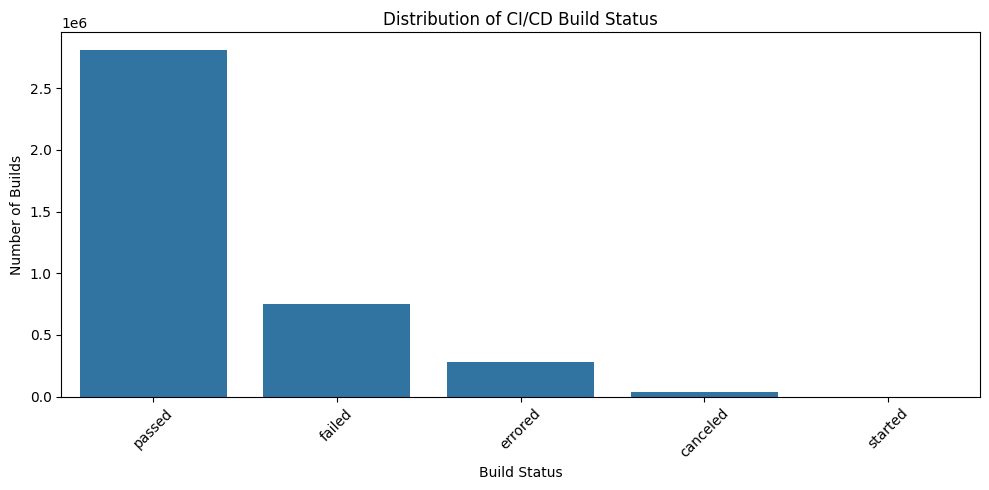

In [20]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=target_distribution,
    x="tr_status",
    y="total_builds"
)

plt.title("Distribution of CI/CD Build Status")
plt.xlabel("Build Status")
plt.ylabel("Number of Builds")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [21]:
target_distribution.to_csv(
    f"{REPORT_DIR}/target_distribution.csv",
    index=False
)

print("Target distribution saved!")

Target distribution saved!


Analysing missing values

In [22]:
# Build missing value analysis query

missing_expressions = []

for column in schema["column_name"]:

    col = '"' + column.replace('"', '""') + '"'

    missing_expressions.append(
        f"""
        SUM(
            CASE
                WHEN {col} IS NULL
                     OR TRIM(CAST({col} AS VARCHAR)) = ''
                THEN 1
                ELSE 0
            END
        ) AS "{column}"
        """
    )

missing_query = f"""
SELECT
    {', '.join(missing_expressions)}
FROM read_csv_auto('{csv_path}')
"""

missing_raw = con.execute(missing_query).df()

missing_values = missing_raw.T.reset_index()

missing_values.columns = [
    "column_name",
    "missing_count"
]

missing_values["missing_percentage"] = (
    missing_values["missing_count"] / total_rows
) * 100

missing_values = missing_values.sort_values(
    by="missing_percentage",
    ascending=False
)

display(missing_values.head(20))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,column_name,missing_count,missing_percentage
59,tr_log_tests_failed,3724807.0,95.950919
6,git_merged_with,3061250.0,78.857710
18,tr_virtual_merged_into,3061250.0,78.857710
49,tr_log_frameworks,1542320.0,39.730118
51,tr_log_bool_tests_failed,1474485.0,37.982690
54,tr_log_num_tests_run,1474485.0,37.982690
53,tr_log_num_tests_failed,1474485.0,37.982690
52,tr_log_num_tests_ok,1474485.0,37.982690
55,tr_log_num_tests_skipped,1474485.0,37.982690
11,git_prev_built_commit,1253942.0,32.301509


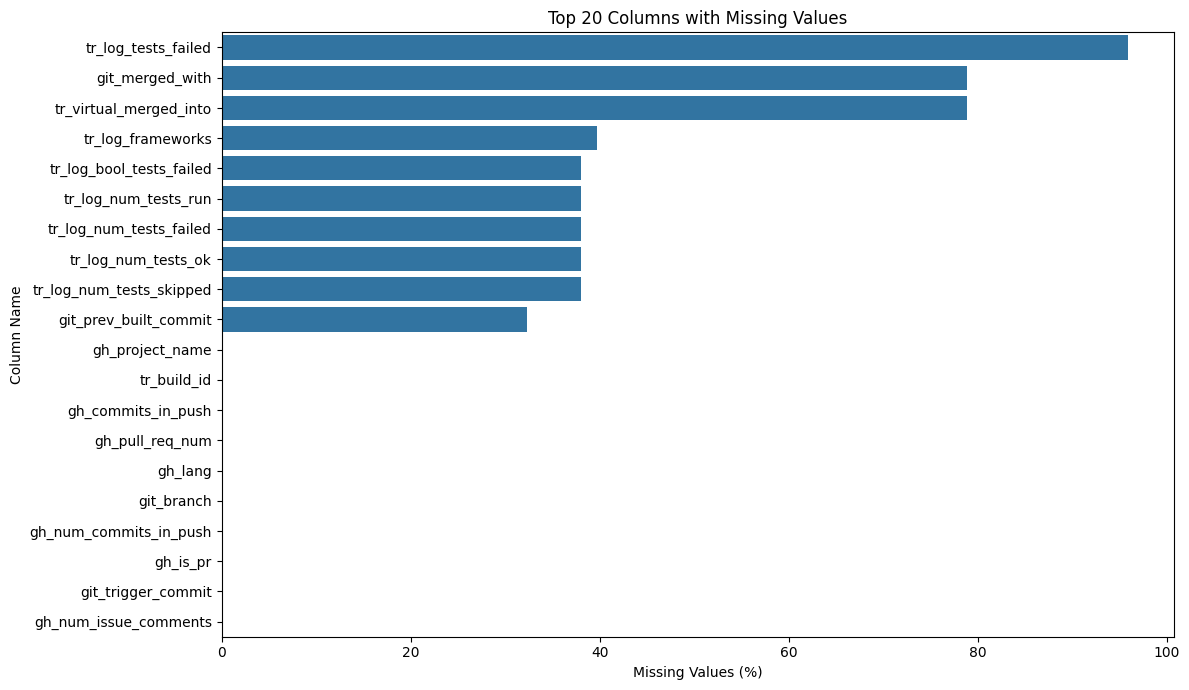

In [23]:
# Display top 20 columns with most missing values

plt.figure(figsize=(12, 7))

sns.barplot(
    data=missing_values.head(20),
    x="missing_percentage",
    y="column_name"
)

plt.title("Top 20 Columns with Missing Values")

plt.xlabel("Missing Values (%)")
plt.ylabel("Column Name")

plt.tight_layout()
plt.show()

In [24]:
missing_values.to_csv(
    f"{REPORT_DIR}/missing_values_report.csv",
    index=False
)

print("Missing value report saved!")

Missing value report saved!


Analyse duplicate values

In [25]:
#Investigate repeated duild IDs
duplicate_build_query = f"""
SELECT
    tr_build_id,
    COUNT(*) AS occurrences
FROM read_csv_auto('{csv_path}')
GROUP BY tr_build_id
HAVING COUNT(*) > 1
ORDER BY occurrences DESC
LIMIT 20
"""

duplicate_builds = con.execute(
    duplicate_build_query
).df()

display(duplicate_builds)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,tr_build_id,occurrences
0,97699584,690
1,67453124,252
2,67452801,252
3,67567287,168
4,67453960,168
5,67453782,168
6,101684885,165
7,102174365,165
8,99033608,165
9,146169710,165


In [26]:
#Investigate repeated job IDs
duplicate_job_query = f"""
SELECT
    tr_job_id,
    COUNT(*) AS occurrences
FROM read_csv_auto('{csv_path}')
GROUP BY tr_job_id
HAVING COUNT(*) > 1
ORDER BY occurrences DESC
LIMIT 20
"""

duplicate_jobs = con.execute(
    duplicate_job_query
).df()

display(duplicate_jobs)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,tr_job_id,occurrences


no  job_id repettion

In [27]:
duplicate_summary_query = f"""
SELECT
    COUNT(*) AS total_records,

    COUNT(DISTINCT tr_build_id)
        AS unique_build_ids,

    COUNT(DISTINCT tr_job_id)
        AS unique_job_ids

FROM read_csv_auto('{csv_path}')
"""

duplicate_summary = con.execute(
    duplicate_summary_query
).df()

display(duplicate_summary)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,total_records,unique_build_ids,unique_job_ids
0,3881992,925897,3881992


Initial statistical summary

In [28]:
# Numerical statistical summary

numerical_names = numerical_columns[
    "column_name"
].tolist()

if numerical_names:

    quoted_columns = ", ".join(
        '"' + c.replace('"', '""') + '"'
        for c in numerical_names
    )

    statistics_query = f"""
    SUMMARIZE
    SELECT {quoted_columns}
    FROM read_csv_auto('{csv_path}')
    """

    numerical_summary = con.execute(
        statistics_query
    ).df()

    display(numerical_summary)

else:

    print("No numerical columns identified.")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,column_name,column_type,min,max,approx_unique,avg,std,q25,q50,q75,count,null_percentage
0,tr_build_id,BIGINT,3154,156676587,956187,66939169.09640051,45639878.37631106,25491050,62613563,104782292,3881992,0.0
1,gh_team_size,BIGINT,0,248,214,22.367849804945504,21.36572925399457,9,17,27,3881992,0.0
2,git_num_all_built_commits,BIGINT,1,9643,448,1.542948311073284,11.081703788512218,1,1,1,3881992,0.0
3,gh_num_commit_comments,BIGINT,0,770,51,0.04254825872902365,0.7524093729649661,0,0,0,3881992,0.0
4,git_diff_src_churn,BIGINT,0,13870,522,1.113429651580941,23.596411574220628,0,0,0,3881992,0.0
5,git_diff_test_churn,BIGINT,0,0,1,0.0,0.0,0,0,0,3881992,0.0
6,gh_diff_files_added,BIGINT,0,19892,514,0.8355591665309975,17.45134594308006,0,0,0,3881992,0.0
7,gh_diff_files_deleted,BIGINT,0,8450,372,0.36460636704042665,9.336714272466166,0,0,0,3881992,0.0
8,gh_diff_files_modified,BIGINT,0,9233,586,4.660904762297295,22.07141327445421,1,2,3,3881992,0.0
9,gh_diff_tests_added,BIGINT,0,560,97,0.0359096566917191,1.4080460810756572,0,0,0,3881992,0.0


Export all initial reports

In [29]:
# Save numerical summary

if numerical_names:
    numerical_summary.to_csv(
        f"{REPORT_DIR}/numerical_summary.csv",
        index=False
    )

# Save duplicate summary

duplicate_summary.to_csv(
    f"{REPORT_DIR}/duplicate_summary.csv",
    index=False
)

print("================================")
print("MILESTONE 01 REPORTS GENERATED")
print("================================")

print("1. dataset_schema.csv")
print("2. dataset_sample.csv")
print("3. target_distribution.csv")
print("4. missing_values_report.csv")
print("5. numerical_summary.csv")
print("6. duplicate_summary.csv")

MILESTONE 01 REPORTS GENERATED
1. dataset_schema.csv
2. dataset_sample.csv
3. target_distribution.csv
4. missing_values_report.csv
5. numerical_summary.csv
6. duplicate_summary.csv


All the reports are generated successfully


# Milestone 01 – Conclusion

## Dataset Understanding Summary

The TravisTorrent dataset was investigated to understand
its structure and suitability for CI/CD build failure
prediction.

The following activities were completed:

1. Dataset structure inspection.
2. Column and data type identification.
3. Sample record investigation.
4. Target variable investigation.
5. Missing value analysis.
6. Duplicate identifier investigation.
7. Initial numerical statistical analysis.
8. Dataset report generation.

## Key Findings

- Total records: [Insert actual result]
- Total columns: [Insert actual result]
- Target column: tr_status (provisional)
- Timestamp candidate: gh_build_started_at
- Most missing feature: [Insert result]
- Target distribution: [Insert result]

## Next Milestone

Milestone 02 – Exploratory Data Analysis (EDA)

The next stage will investigate build failure patterns,
feature distributions, relationships and correlations.
